# Exploratory Data Analysis of the Abalone dataset

The goal of the project is to predict the **age of an abalone** from physical measurements that are quick to take,
instead of cutting the shell, staining it and counting its rings under a microscope.

The age is derived from the number of rings: **age (years) = rings + 1.5**, so the target we model is `Rings`.

Dataset: [Kaggle - Abalone dataset](https://www.kaggle.com/datasets/rodolfomendes/abalone-dataset), originally from
the UCI Machine Learning Repository. The continuous measurements were divided by 200 by the dataset authors
(lengths in mm, weights in grams).

# Imports

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 500)
sns.set_theme(style="whitegrid")

# Data

In [2]:
df = pd.read_csv("../data/abalone.csv")
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 297.9 KB


In [4]:
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicated rows: {df.duplicated().sum()}")

Missing values: 0
Duplicated rows: 0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
Diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
Height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
Whole weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
Shucked weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
Viscera weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
Shell weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
Rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


# EDA

## Target: number of rings

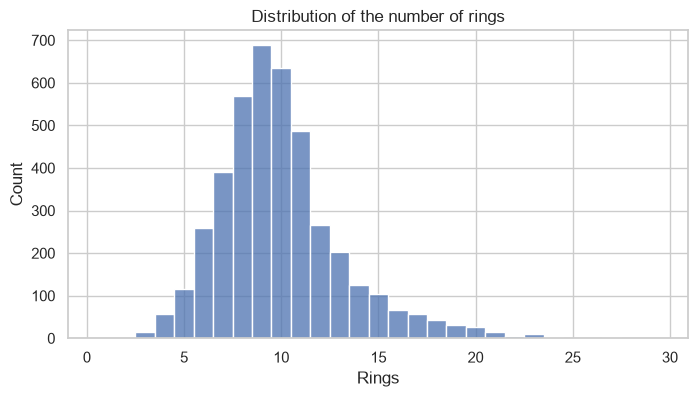

Skewness: 1.11
Share of abalones with 7 to 11 rings: 66%


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["Rings"], discrete=True, ax=ax)
ax.set(title="Distribution of the number of rings", xlabel="Rings", ylabel="Count")
plt.show()

print(f"Skewness: {df['Rings'].skew():.2f}")
print(f"Share of abalones with 7 to 11 rings: {df['Rings'].between(7, 11).mean():.0%}")

Two thirds of the abalones have between 7 and 11 rings (8.5 to 12.5 years old), but the distribution has a long
right tail (up to 29 rings). Old abalones are rare, so they will be the hardest to predict and will weigh a lot in
the RMSE.

## Sex

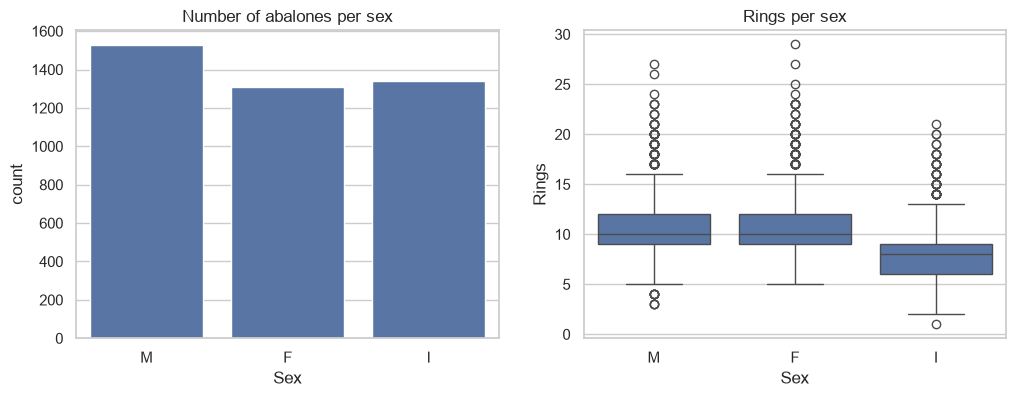

,mean,median,std
Sex,,,
F,11.13,10.0,3.10
I,7.89,8.0,2.51
M,10.71,10.0,3.03


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Sex", order=["M", "F", "I"], ax=axes[0])
axes[0].set_title("Number of abalones per sex")
sns.boxplot(data=df, x="Sex", y="Rings", order=["M", "F", "I"], ax=axes[1])
axes[1].set_title("Rings per sex")
plt.show()

df.groupby("Sex")["Rings"].agg(["mean", "median", "std"]).round(2)

The three classes are balanced. Infants (`I`) have far fewer rings (median 8) than adults, while males and females
are very similar (median 10). `Sex` is therefore a useful categorical feature, which we will one-hot encode.

## Correlations between the measurements

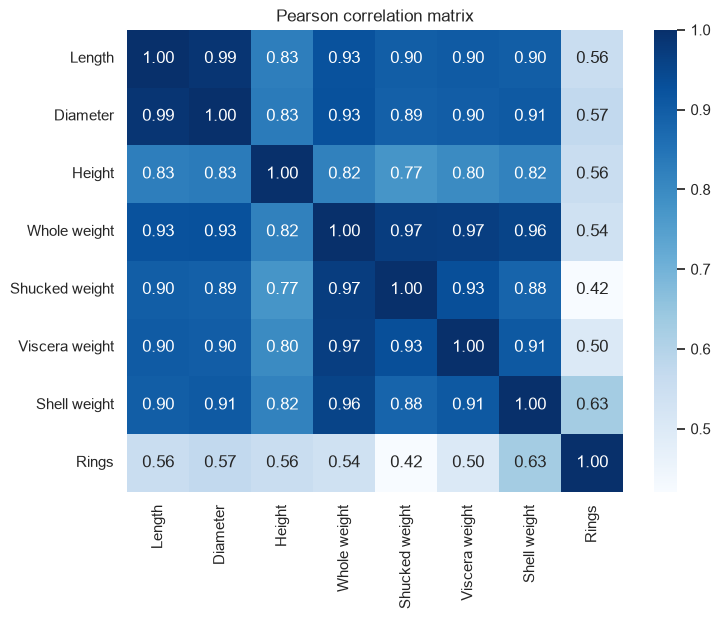

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df.drop(columns="Sex").corr(), annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_title("Pearson correlation matrix")
plt.show()

- All size and weight measurements are strongly correlated with each other (0.77 to 0.99): they mostly describe the
  size of the animal. Linear models will suffer from this multicollinearity, tree-based models will not.
- `Shell weight` is the measurement the most correlated with the number of rings (0.63), the correlations with the
  target stay moderate (0.42 to 0.63).

## Rings vs measurements

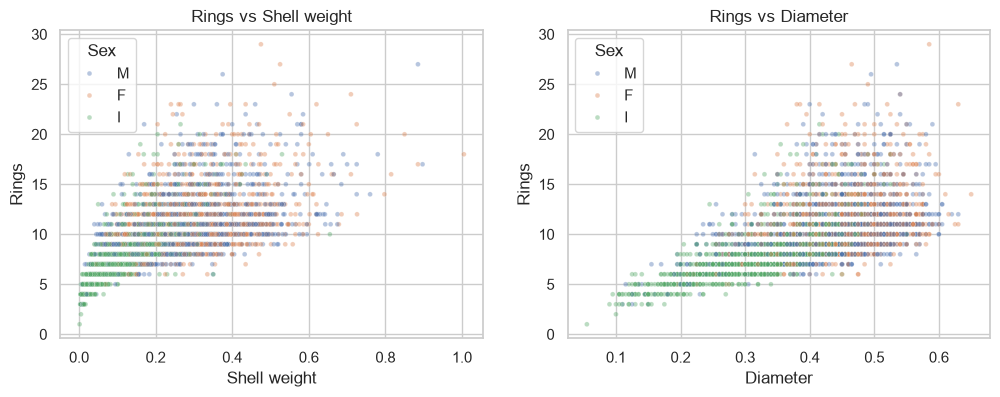

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ["Shell weight", "Diameter"], strict=True):
    sns.scatterplot(data=df, x=column, y="Rings", hue="Sex", alpha=0.4, s=12, ax=ax)
    ax.set_title(f"Rings vs {column}")
plt.show()

The number of rings increases with the size of the abalone, but not linearly: growth slows down for the biggest
animals. The spread of the rings also increases with the size (heteroscedasticity): big abalones can be of very
different ages, so the prediction errors will be larger for them. Non-linear models such as tree ensembles should
capture this relationship better than a linear regression.

## Anomalies

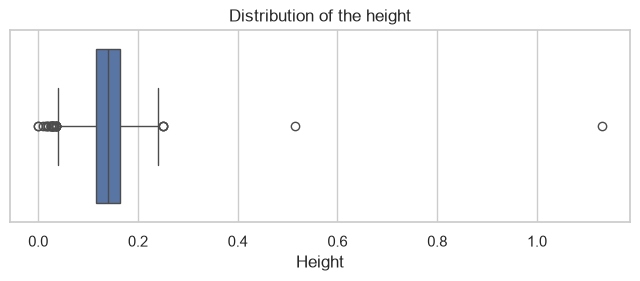

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
1257,I,0.430,0.340,0.000,0.428,0.2065,0.0860,0.1150,8
1417,M,0.705,0.565,0.515,2.210,1.1075,0.4865,0.5120,10
2051,F,0.455,0.355,1.130,0.594,0.3320,0.1160,0.1335,8
3996,I,0.315,0.230,0.000,0.134,0.0575,0.0285,0.3505,6


In [10]:
fig, ax = plt.subplots(figsize=(8, 2.5))
sns.boxplot(x=df["Height"], ax=ax)
ax.set_title("Distribution of the height")
plt.show()

df[(df["Height"] == 0) | (df["Height"] > 0.4)]

Two abalones have a height of 0 and two others have heights of 0.515 and 1.13, whereas all the other heights are
at most 0.25 (one of them is even taller than its diameter). These are measurement or typing errors: we remove these
4 rows (out of 4,177) before training.

In [11]:
parts_weight = df[["Shucked weight", "Viscera weight", "Shell weight"]].sum(axis=1)
heavier_parts = (parts_weight > df["Whole weight"]).sum()
print(f"Rows where the parts weigh more than the whole abalone: {heavier_parts}")

Rows where the parts weigh more than the whole abalone: 155


For 155 abalones the sum of the parts weighs more than the whole abalone, probably because of the water lost or
absorbed when shucking and drying. The differences are small, so we keep these rows.

# Conclusions

- The dataset is clean: 4,177 abalones, 8 features, no missing values and no duplicates.
- The target `Rings` is right-skewed (median 9, 95% of the abalones have 16 rings or less): old abalones are rare
  and hard to predict.
- `Sex` is informative mainly to separate infants from adults: it is one-hot encoded.
- The measurements are strongly correlated with each other, and `Shell weight` is the best single predictor.
- The relationship between the measurements and the rings is non-linear and heteroscedastic: we will compare
  linear models with tree-based ensembles.
- Preprocessing used for the modelling: rename the columns to snake_case, remove the 4 impossible heights
  (0 or above 0.4), one-hot encode `sex` and scale the numerical features.